# ANN Regression

In [17]:
import pandas as pd
import numpy as np

# Loading the Dataset

In [18]:
df = pd.read_csv("/content/powerplant_data.csv")

In [19]:
df.head()

,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43


In [20]:
df.isnull().sum()

,0
AT,0
V,0
AP,0
RH,0
PE,0


In [21]:
X = df.drop("PE", axis=1)
Y = df["PE"]

In [22]:
X.head()

,AT,V,AP,RH
0,8.34,40.77,1010.84,90.01
1,23.64,58.49,1011.40,74.20
2,29.74,56.90,1007.15,41.91
3,19.07,49.69,1007.22,76.79
4,11.80,40.66,1017.13,97.20


# Converting Dataset into Tensors

In [23]:
# Split out data

from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

In [24]:
# Scaling the data

from sklearn.preprocessing import StandardScaler

scale = StandardScaler()

X_train_scale = scale.fit_transform(X_train)
X_test_scale = scale.transform(X_test)

In [25]:
X_train_scale

array([[ 0.74805289,  0.72006931, -0.32660017, -0.49711722],
       [ 0.86181948,  1.26515721, -0.98521113,  0.8181501 ],
       [ 0.93409473,  1.52314975,  0.32523844,  0.80167494],
       ...,
       [-0.22097078, -0.834965  ,  0.36756563, -0.83554456],
       [ 0.94747903,  1.14245344, -0.41971997, -0.45455637],
       [-1.77355014, -1.19049131,  1.92520594,  0.91837402]])

In [26]:
import torch
import torch.nn as nn

X_train_tensor = torch.tensor(X_train_scale, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scale, dtype=torch.float32)

Y_train_tensor = torch.tensor(Y_train.values, dtype=torch.float32).view(-1, 1)
Y_test_tensor = torch.tensor(Y_test.values, dtype=torch.float32).view(-1, 1)

# Tensor Dataset and DataLoader

In [27]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(X_train_tensor, Y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, Y_test_tensor)

In [28]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32)

# Building ANN Model

In [29]:
# Define the ANN Model

class ANNModel(nn.Module):
  def __init__(self):
    super(ANNModel, self).__init__()

    self.model = nn.Sequential(
        # 1st Hidden Layer
        nn.Linear(X_train.shape[1],6),
        nn.ReLU(),

        # 2nd Hidden Layer
        nn.Linear(6,6),
        nn.ReLU(),

        # Ouput Layer
        nn.Linear(6,1)
    )

  def forward(self, x):
    return self.model(x)

In [30]:
import torch.optim as optim

model = ANNModel()

loss = nn.MSELoss()
optimizer = optim.Adam(model.parameters())

# Training the ANN Model

In [31]:
training_loss = []
testing_loss = []
best_val_loss = float("inf")

epochs = 100

for ep in range(epochs):
  model.train()

  running_loss = 0.0 # total training loss for 1 epoch

  for xb, yb in train_loader:
    # xb -> features of 1 batch
    # yb -> labels of 1 batch

    optimizer.zero_grad() # reset gradients to zero for new batch

    op = model(xb) # forward prop...predicted outputs for this batch
    ls = loss(op, yb) # compute loss
    ls.backward() # back prop...compute gradients

    optimizer.step() # params like weights, bias are updated

    running_loss += ls.item() # ls will be in tensor, we use item() to convert it into python float

  ep_train_loss = running_loss / len(train_loader)
  training_loss.append(ep_train_loss)


  # Validation
  model.eval() # changing the mode form train to evaluation
  running_val_loss = 0.0

  with torch.no_grad(): # no gradients compute
    for xb,yb in test_loader:
      op = model(xb)
      ls = loss(op, yb)
      running_val_loss += ls.item()

  ep_test_loss = running_val_loss / len(test_loader)
  testing_loss.append(ep_test_loss)

  print(f"Epoch {ep+1}/{epochs} => Training Loss: {ep_train_loss} and Testing Loss: {ep_test_loss}")

  if ep_test_loss < best_val_loss:
    best_val_loss = ep_test_loss
    torch.save(model.state_dict(), "best_model.pth")

Epoch 1/100 => Training Loss: 205530.77903645832 and Testing Loss: 202589.23098958333
Epoch 2/100 => Training Loss: 193677.70638020834 and Testing Loss: 179510.86432291666
Epoch 3/100 => Training Loss: 157168.16640625 and Testing Loss: 132141.39205729167
Epoch 4/100 => Training Loss: 109772.52026367188 and Testing Loss: 89628.0625
Epoch 5/100 => Training Loss: 76153.5306640625 and Testing Loss: 62486.06953125
Epoch 6/100 => Training Loss: 51844.96530761719 and Testing Loss: 39721.272298177086
Epoch 7/100 => Training Loss: 31123.120865885416 and Testing Loss: 21866.678597005208
Epoch 8/100 => Training Loss: 16479.49655761719 and Testing Loss: 10974.666723632812
Epoch 9/100 => Training Loss: 8443.255208333334 and Testing Loss: 6104.6112060546875
Epoch 10/100 => Training Loss: 5385.020659383138 and Testing Loss: 4445.118298339844
Epoch 11/100 => Training Loss: 4131.234824625651 and Testing Loss: 3513.5486572265627
Epoch 12/100 => Training Loss: 3309.570988972982 and Testing Loss: 2848.457

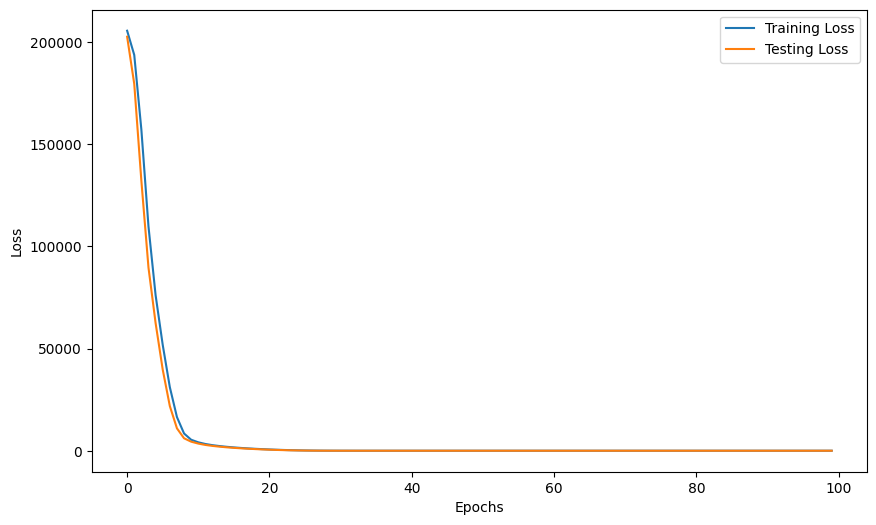

In [32]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

plt.plot(training_loss, label="Training Loss")
plt.plot(testing_loss, label="Testing Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

# Loading Best Model

In [34]:
# Loading the best Model from .pth file

model.load_state_dict(torch.load("best_model.pth"))

<All keys matched successfully>

# Model Evaluation

In [35]:
model.eval()
with torch.no_grad():
  train_op = model(X_train_tensor)
  test_op = model(X_test_tensor)

  train_loss = loss(train_op, Y_train_tensor)
  test_loss = loss(test_op, Y_test_tensor)

print("Training MSE: ", train_loss.item())
print("Testing MSE: ", test_loss.item())

Training MSE:  20.65394401550293
Testing MSE:  18.993534088134766


In [37]:
from sklearn.metrics import r2_score

print("R2 Score: ", r2_score(Y_test, test_op)*100)

R2 Score:  93.36224988880666


In [39]:
predicted_df = pd.DataFrame(test_op.numpy(), columns=["Predicted"])
actual_df = pd.DataFrame(Y_test.values, columns=["Actual"])

result_df = pd.concat([actual_df, predicted_df], axis=1)
result_df

,Actual,Predicted
0,433.27,435.601624
1,438.16,436.936218
2,458.42,461.051666
3,480.82,475.695038
4,441.41,435.639984
...,...,...
1909,456.70,451.162018
1910,438.04,431.828156
1911,467.80,467.518463
1912,437.14,431.255981
